In [2]:
from shapely.geometry import Polygon, Point
import shapely
import numpy as np
import matplotlib.pyplot as plt
import random
from scipy.spatial import Voronoi, voronoi_plot_2d

In [3]:
# Function to create a circle polygon
def create_circle(center, radius, num_points=100):
    angles = np.linspace(0, 2*np.pi, num_points)
    x = center[0] + radius * np.cos(angles)
    y = center[1] + radius * np.sin(angles)
    return Polygon(np.column_stack((x, y)))

In [4]:
# Function to create a triangle polygon
def create_triangle(vertices):
    return Polygon(vertices)

In [5]:
# Function to create a rectangle polygon
def create_rectangle(lower_left, upper_right):
    return Polygon([lower_left, (lower_left[0], upper_right[1]), upper_right, (upper_right[0], lower_left[1])])

In [6]:
# Create a circle
circle_center = (0, 0)
circle_radius = 1
circle_polygon = create_circle(circle_center, circle_radius)

# Create a triangle
triangle_vertices = [(-1, -1), (1, -1), (0, 1)]
triangle_polygon = create_triangle(triangle_vertices)

# Create a rectangle
rectangle_lower_left = (-1, -1)
rectangle_upper_right = (1, 1)
rectangle_polygon = create_rectangle(rectangle_lower_left, rectangle_upper_right)

# Create giant rectangle
rectangle_lower_left = (-50, -50)
rectangle_upper_right = (50, 50)
giant_rectangle = create_rectangle(rectangle_lower_left, rectangle_upper_right)

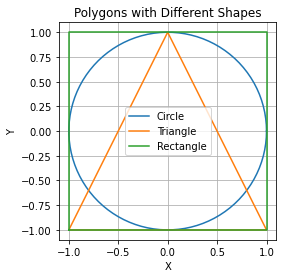

In [7]:
# Plot polygons
plt.figure()
plt.plot(*circle_polygon.exterior.xy, label='Circle')
plt.plot(*triangle_polygon.exterior.xy, label='Triangle')
plt.plot(*rectangle_polygon.exterior.xy, label='Rectangle')
plt.gca().set_aspect('equal', adjustable='box')
plt.legend()
plt.title('Polygons with Different Shapes')
plt.xlabel('X')
plt.ylabel('Y')
plt.grid(True)
plt.show()


In [8]:
def generate_points(n: int, shape: Polygon):
    """
    param n: Number of points to be generated
    """
    points = []
    i = 0
    while i < n: 
        x = random.uniform(-1, 1)
        y = random.uniform(-1, 1)
        point = Point(x, y)

        if shape.contains(point):
            points.append(point)
            i += 1
    return points

In [9]:
def points_on_polygon_boundary(polygon, n):
    # Ensure input is a Polygon
    if not isinstance(polygon, Polygon):
        raise ValueError("Input must be a Shapely Polygon")

    # Get the linear ring (boundary) of the polygon
    boundary = polygon.boundary

    # Compute the length of the linear ring
    ring_length = boundary.length

    # Sample points along the linear ring
    step = ring_length / n
    sampled_points = []
    distance = 0.0
    while len(sampled_points) < n:
        point = boundary.interpolate(distance)
        sampled_points.append(np.array([point.x, point.y]))
        distance += step

    return sampled_points

In [10]:
def cell_polygons(points, shape):
    # generate points on the boundary of a giant rectangle around the polygon
    boundary_points = points_on_polygon_boundary(giant_rectangle, 1000)

    # get all points in one array
    all_points = np.vstack((boundary_points, points))

    # compute voronoi
    voronoi = Voronoi(all_points)

    # Extract Voronoi cells as Shapely polygons
    voronoi_polygons = []
    for region in voronoi.regions:
        if len(region) > 0 and region[0] != -1:
            vertices = [voronoi.vertices[i] for i in region]

            # check if at least one of the vertices is inside the shape
            contained = False
            for vertice in vertices:
                point = Point(vertice[0], vertice[1])
                if shape.contains(point):
                    contained = True

            if contained:
                polygon = Polygon(vertices)
                voronoi_polygons.append(polygon)

    # cut off everything not contained by the outer shape
    inner_polygons = []
    for polygon in voronoi_polygons:
        inner_polygons.append(polygon.intersection(shape))
        
    return inner_polygons

In [11]:
# generate random points in polygon
points = generate_points(10, circle_polygon)
points = np.array([[point.x, point.y] for point in points])

In [12]:
voronoi_polygons = cell_polygons(points, circle_polygon)

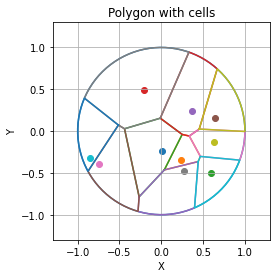

In [13]:
plt.figure()
plt.plot(*circle_polygon.exterior.xy)

for point in points:
    plt.scatter(point[0], point[1])

for cell in voronoi_polygons:
    plt.plot(*cell.exterior.xy)

plt.gca().set_aspect('equal', adjustable='box')
plt.title('Polygon with cells')
plt.xlabel('X')
plt.ylabel('Y')
plt.grid(True)
plt.xlim([-1.3, 1.3])
plt.ylim([-1.3, 1.3])
plt.show()

In [19]:
# generate random points in polygon
points = generate_points(10, triangle_polygon)
points = np.array([[point.x, point.y] for point in points])
voronoi_polygons = cell_polygons(points, triangle_polygon)

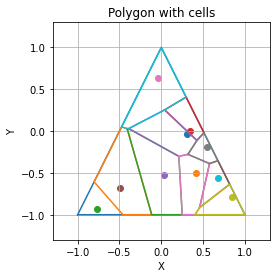

In [20]:
plt.figure()
plt.plot(*triangle_polygon.exterior.xy)

for point in points:
    plt.scatter(point[0], point[1])

for cell in voronoi_polygons:
    plt.plot(*cell.exterior.xy)

plt.gca().set_aspect('equal', adjustable='box')
plt.title('Polygon with cells')
plt.xlabel('X')
plt.ylabel('Y')
plt.grid(True)
plt.xlim([-1.3, 1.3])
plt.ylim([-1.3, 1.3])
plt.show()

In [42]:
def compare_points(old_points, new_points):
    max_delta = 0.0001

    for i in range(len(old_points)):
        delta = np.sqrt((old_points[i,0] - new_points[i,0])**2 + (old_points[i,1] - new_points[i,1])**2)
        if delta > max_delta :
            return False
    return True

In [43]:
def goal_generation (polygon, n):
    # generate random points in polygon
    points = generate_points(n, polygon)
    points = np.array([[point.x, point.y] for point in points])
    old_centroids = None

    i = True
    while i:
        voronoi_polygons = cell_polygons(points, polygon)
        centroids = [shapely.centroid(cell) for cell in voronoi_polygons]
        points = np.array([[point.x, point.y] for point in centroids])

        if old_centroids is not None:
            if compare_points(points, old_centroids):
                i = False
        
        
        old_centroids = points
    return points

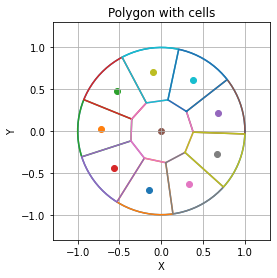

In [45]:
polygon = circle_polygon
goal_positions = goal_generation(polygon, 10)
voronoi_polygons = cell_polygons(goal_positions, polygon)

plt.figure()
plt.plot(*polygon.exterior.xy)

for point in goal_positions:
    plt.scatter(point[0], point[1])

for cell in voronoi_polygons:
    plt.plot(*cell.exterior.xy)

plt.gca().set_aspect('equal', adjustable='box')
plt.title('Polygon with cells')
plt.xlabel('X')
plt.ylabel('Y')
plt.grid(True)
plt.xlim([-1.3, 1.3])
plt.ylim([-1.3, 1.3])
plt.show()

In [39]:
goal_positions

array([[-2.26573671e-01,  9.74212411e-02],
       [-4.51476540e-01, -3.55599955e-01],
       [ 2.21580828e-01,  1.03440915e-01],
       [ 2.28084457e-01, -7.77969372e-01],
       [-2.21796144e-01, -7.79817059e-01],
       [-3.87644795e-04, -3.37369403e-01],
       [ 4.49160171e-01, -3.48163703e-01],
       [-1.11506250e-03,  5.66378043e-01],
       [-6.80725246e-01, -7.95772796e-01],
       [ 6.81849414e-01, -7.93512281e-01]])